# Hyperscalers vs. Semiconductors
## First research notebook

**Question.** How closely do the two baskets move together, and how much broad equity-market exposure remains after putting equal dollars on each side?

| Sleeve | Tickers and target weights within the sleeve |
|---|---|
| Long hyperscalers | AMZN, MSFT, GOOGL at one-third each |
| Semiconductor basket to short | SMH 75%, DRAM 25% |
| Broad equity benchmark | SPY |

The notebook models a hypothetical portfolio with equal long and short gross exposure at the start of each session. Returns are measured against gross exposure. The analysis excludes borrow, financing and trading costs. Broker fills and position drift belong in a later trade attribution analysis.

### 1. Choose a price source

Run all cells with `DATA_SOURCE = "demo"` to verify the notebook on your computer. All demo data are simulated, even though the columns use real tickers.

For market data, install `yfinance` in your notebook kernel by running `%pip install yfinance` in a separate cell. Change the setting below to `"yahoo"` and rerun all cells. The download uses adjusted closing prices and starts on DRAM's April 2, 2026 launch date. It excludes the current New York calendar date, so its closing bar cannot be partial. Check the printed sample dates and coverage before interpreting results.

Sources: [Roundhill DRAM fund page](https://roundhillinvestments.com/etf/dram/) and [yfinance download documentation](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html).

In [22]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_SOURCE = "yahoo"  # Change to "yahoo" for historical market data.

LONG = ["AMZN", "MSFT", "GOOGL"]
SHORT = {"SMH": 0.75, "DRAM": 0.25}
BENCHMARK = "SPY"
TICKERS = LONG + list(SHORT) + [BENCHMARK]
FIRST_DATE = "2026-04-02"
WINDOW = 30

if DATA_SOURCE == "demo":
    rng = np.random.default_rng(42)
    dates = pd.bdate_range(FIRST_DATE, periods=160)
    market = rng.normal(0.0004, 0.009, len(dates))
    exposures = np.array([0.9, 1.0, 0.95, 1.4, 1.6, 1.0])
    noise = rng.normal(0, 0.007, (len(dates), len(TICKERS)))
    noise[:, -1] = 0
    simulated_returns = market[:, None] * exposures + noise
    prices = 100 * (1 + pd.DataFrame(simulated_returns, index=dates, columns=TICKERS)).cumprod()
    source_label = "SIMULATED DEMO"
elif DATA_SOURCE == "yahoo":
    import yfinance as yf

    end = pd.Timestamp.now(tz="America/New_York").date().isoformat()
    download = yf.download(
        TICKERS,
        start=FIRST_DATE,
        end=end,
        interval="1d",
        auto_adjust=True,
        group_by="column",
        multi_level_index=True,
        progress=False,
    )
    if download is None or download.empty or "Close" not in download.columns.get_level_values(0):
        raise RuntimeError("No closing prices returned. Check the data connection and try again.")
    prices = download["Close"].reindex(columns=TICKERS)
    source_label = "Yahoo Finance adjusted closing prices"
else:
    raise ValueError('Set DATA_SOURCE to "demo" or "yahoo".')

prices = prices.sort_index()
unavailable = prices.columns[prices.isna().all()].tolist()
if unavailable:
    raise RuntimeError(f"No price history returned for: {', '.join(unavailable)}")
print(source_label)
print(f"Price dates: {prices.index[0]:%Y-%m-%d} to {prices.index[-1]:%Y-%m-%d}")
prices.tail()

Yahoo Finance adjusted closing prices
Price dates: 2026-04-02 to 2026-11-20


Ticker,AMZN,MSFT,GOOGL,SMH,DRAM,SPY
Date,,,,,,
2026-11-16,257.750000,516.991272,283.720001,461.899994,39.270000,739.950012
2026-11-17,257.890015,505.263947,280.200012,460.100006,38.930000,732.440002
2026-11-18,267.739990,507.309998,282.440002,459.540009,39.150002,730.200012
2026-11-19,257.369995,498.299988,272.660004,447.480011,38.430000,715.869995
2026-11-20,246.820007,484.519989,265.290009,400.059998,33.360001,689.809998


### 2. Build both baskets

`pct_change(fill_method=None)` calculates the daily change in each adjusted close. We keep dates with usable returns for all six tickers.

The semiconductor basket below is shown as a positive-weight basket to measure how the underlying assets move. In the portfolio calculation, its return is subtracted because the exposure is short. If hyperscalers rise 2% and semis rise 1%, the hypothetical portfolio gains **0.5% of gross exposure** before costs.

In [24]:
asset_returns = prices.pct_change(fill_method=None).dropna()
if len(asset_returns) < WINDOW:
    raise RuntimeError(f"Need at least {WINDOW} dates with returns for every ticker.")

returns = pd.DataFrame(index=asset_returns.index)
returns["Hyperscalers"] = asset_returns[LONG].mean(axis=1)
returns["Semiconductors"] = asset_returns[list(SHORT)].mul(pd.Series(SHORT)).sum(axis=1)
returns["Market"] = asset_returns[BENCHMARK]
returns["Long/short on gross exposure"] = 0.5 * (
    returns["Hyperscalers"] - returns["Semiconductors"]
)

print(f"Matched return sample: {len(returns)} days")
print(f"Return dates: {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")
print(f"Price rows excluded from returns: {len(prices) - len(returns)} (includes the first row)")
returns.tail().mul(100).round(2).add_suffix(" (%)")

Matched return sample: 161 days
Return dates: 2026-04-06 to 2026-11-20
Price rows excluded from returns: 1 (includes the first row)


,Hyperscalers (%),Semiconductors (%),Market (%),Long/short on gross exposure (%)
Date,,,,
2026-11-16,-2.85,-5.67,-1.91,1.41
2026-11-17,-1.15,-0.51,-1.01,-0.32
2026-11-18,1.67,0.05,-0.31,0.81
2026-11-19,-3.04,-2.43,-1.96,-0.30
2026-11-20,-3.19,-11.25,-3.64,4.03


### 3. Read the charts and estimate beta

The top chart compounds the two baskets' daily returns separately. The lower chart asks how closely the two baskets moved together over each trailing 30-observation window.

The beta is the slope of a simple regression of the long/short return on SPY returns, with an intercept. Dividing the covariance by SPY's variance gives that slope directly. A beta of +0.20 would mean a +1% SPY move was associated with approximately +0.20% on gross exposure, based on the fitted relationship.

Full-sample basket correlation: +0.23
Long/short beta to SPY: -0.87


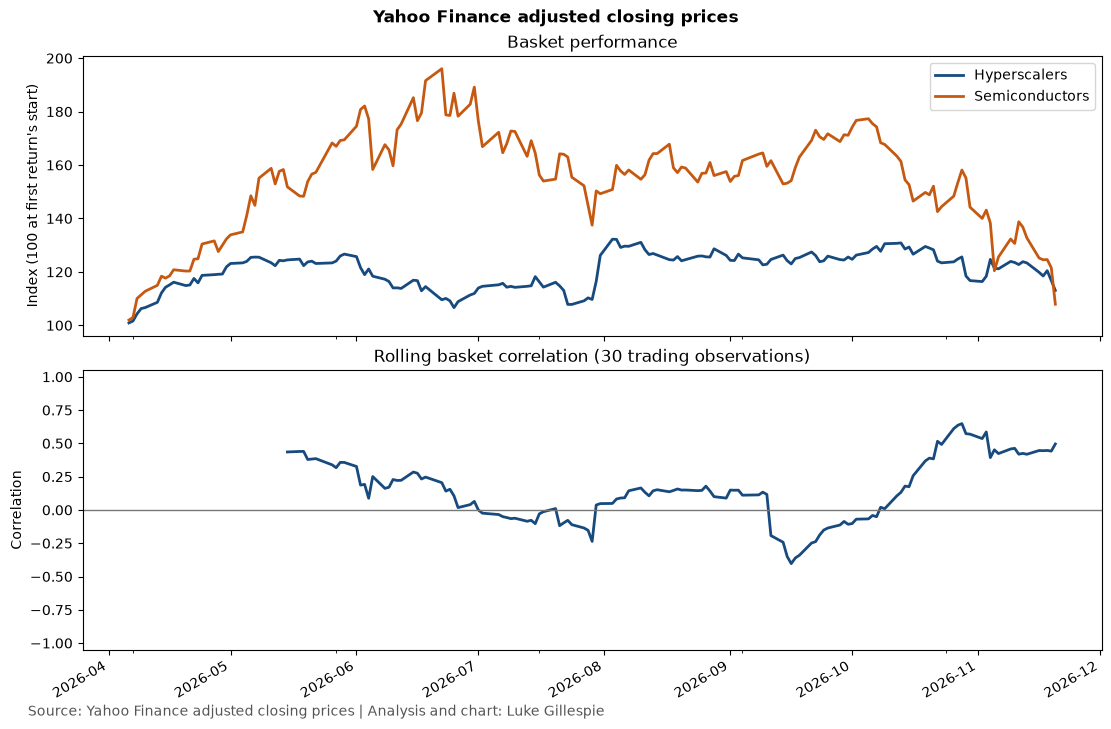

Hyperscalers since Nov. 5 close: -6.85%
Semiconductors since Nov. 5 close: -10.40%
Modeled P&L as % of fixed gross exposure: +1.36%


In [25]:
long_leg = returns["Hyperscalers"]
short_basket = returns["Semiconductors"]
spread = returns["Long/short on gross exposure"]
market = returns["Market"]
rolling_corr = long_leg.rolling(WINDOW).corr(short_basket)
market_variance = market.var()
if market_variance <= 0:
    raise RuntimeError("The market benchmark needs variable returns to estimate beta.")

print(f"Full-sample basket correlation: {long_leg.corr(short_basket):+.2f}")
print(f"Long/short beta to {BENCHMARK}: {spread.cov(market) / market_variance:+.2f}")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
fig.suptitle(source_label, fontweight="bold")
basket_returns = returns[["Hyperscalers", "Semiconductors"]]
basket_index = (1 + basket_returns).cumprod() * 100
basket_index.plot(ax=axes[0], color=["#174A7E", "#C65911"], linewidth=2)
axes[0].set_title("Basket performance")
axes[0].set_ylabel("Index (100 at first return's start)")

rolling_corr.plot(ax=axes[1], color="#174A7E", linewidth=2)
axes[1].axhline(0, color="#777777", linewidth=1)
axes[1].set_ylim(-1.05, 1.05)
axes[1].set_title(f"Rolling basket correlation ({WINDOW} trading observations)")
axes[1].set_ylabel("Correlation")
axes[1].set_xlabel("")
fig.text(
    0.02, -0.015,
    f"Source: {source_label} | Analysis and chart: Luke Gillespie",
    fontsize=10,
    color="#555555",
)
fig.savefig("hyperscalers_vs_semiconductors.png", dpi=250, bbox_inches="tight")
plt.show()

since_entry = returns.loc["2026-11-06":]

for basket in ["Hyperscalers", "Semiconductors"]:
    total_return = (1 + since_entry[basket]).prod() - 1
    print(f"{basket} since Nov. 5 close: {total_return:+.2%}")

trade_return = since_entry["Long/short on gross exposure"].sum()
print(f"Modeled P&L as % of fixed gross exposure: {trade_return:+.2%}")

### 4. Interpret the market-data run

- Did rolling correlation stay close to the full-sample estimate, or did it change over time?
- How large was the spread's market beta and what does its sign imply?
- Which dated power, grid-connection or permitting announcements could help test the original thesis? This first pass measures market exposure and basket behavior. A follow-up event study would examine the thesis more directly.

For a research portfolio on GitHub, document the sample window, weighting convention, sources, findings and limitations in the README.

In [26]:
entry_close = "2026-11-05"
report_end = "2026-11-20"
spread_column = "Long/short on gross exposure"

aligned = returns[["Market", spread_column]].dropna().sort_index()
before_entry = aligned.loc[:entry_close]
trade_window = aligned.loc["2026-11-06":report_end]

market_before_entry = before_entry["Market"]
spread_before_entry = before_entry[spread_column]

beta = spread_before_entry.cov(market_before_entry) / market_before_entry.var()
intercept = spread_before_entry.mean() - beta * market_before_entry.mean()

modeled_pnl = trade_window[spread_column].sum()
spy_pnl = beta * trade_window["Market"].sum()
baseline_pnl = intercept * len(trade_window)
unexplained_pnl = modeled_pnl - spy_pnl - baseline_pnl

print(f"Pre-entry SPY beta:        {beta:+.2f} ({len(before_entry)} trading days)")
print(f"Modeled trade P&L:         {modeled_pnl:+.2%}")
print(f"SPY-linked contribution:   {spy_pnl:+.2%}")
print(f"Pre-entry baseline:        {baseline_pnl:+.2%}")
print(f"Unexplained by SPY model:   {unexplained_pnl:+.2%}")

Pre-entry SPY beta:        -0.87 (150 trading days)
Modeled trade P&L:         +1.36%
SPY-linked contribution:   +5.13%
Pre-entry baseline:        +0.55%
Unexplained by SPY model:   -4.31%


In [27]:
recent_data = returns.sort_index().loc[:"2026-11-20"]
spread_column = "Long/short on gross exposure"

windows = {
    "Previous 30 sessions": recent_data.iloc[-60:-30],
    "Latest 30 sessions": recent_data.iloc[-30:],
}

for label, sample in windows.items():
    long_return = (1 + sample["Hyperscalers"]).prod() - 1
    semis_return = (1 + sample["Semiconductors"]).prod() - 1
    spread = sample[spread_column]
    spy = sample["Market"]
    beta = spread.cov(spy) / spy.var()

    print(f"\n{label} ({sample.index[0]:%b %d} to {sample.index[-1]:%b %d})")
    print(f"Hyperscalers:          {long_return:+.2%}")
    print(f"Semiconductors:        {semis_return:+.2%}")
    print(f"Modeled long/short:    {spread.sum():+.2%}")
    print(f"SPY beta:              {beta:+.2f}")


Previous 30 sessions (Aug 28 to Oct 09)
Hyperscalers:          +3.97%
Semiconductors:        +4.20%
Modeled long/short:    -0.33%
SPY beta:              -0.15

Latest 30 sessions (Oct 12 to Nov 20)
Hyperscalers:          -13.39%
Semiconductors:        -35.66%
Modeled long/short:    +13.56%
SPY beta:              -0.85


Yahoo Finance adjusted closing prices
Shared dates: 2026-05-19 to 2026-11-20 (130 sessions)
Sessions skipped after the comparison started: 0
Starting model equity: $100,000 | Daily gross exposure: $100,000
Latest target weights: 71.7% long / 28.3% short
                            Dollar-neutral 50/50  SPY beta target
Cumulative P&L ($)                      7,471.59         2,928.28
P&L after Nov. 5 close ($)              1,364.73        -3,246.07
Realized beta to SPY                       -0.87            -0.01
Annualized volatility (%)                  34.13            27.15
Maximum drawdown (%)                      -21.32           -17.91
Annualized Sharpe                           0.58             0.34


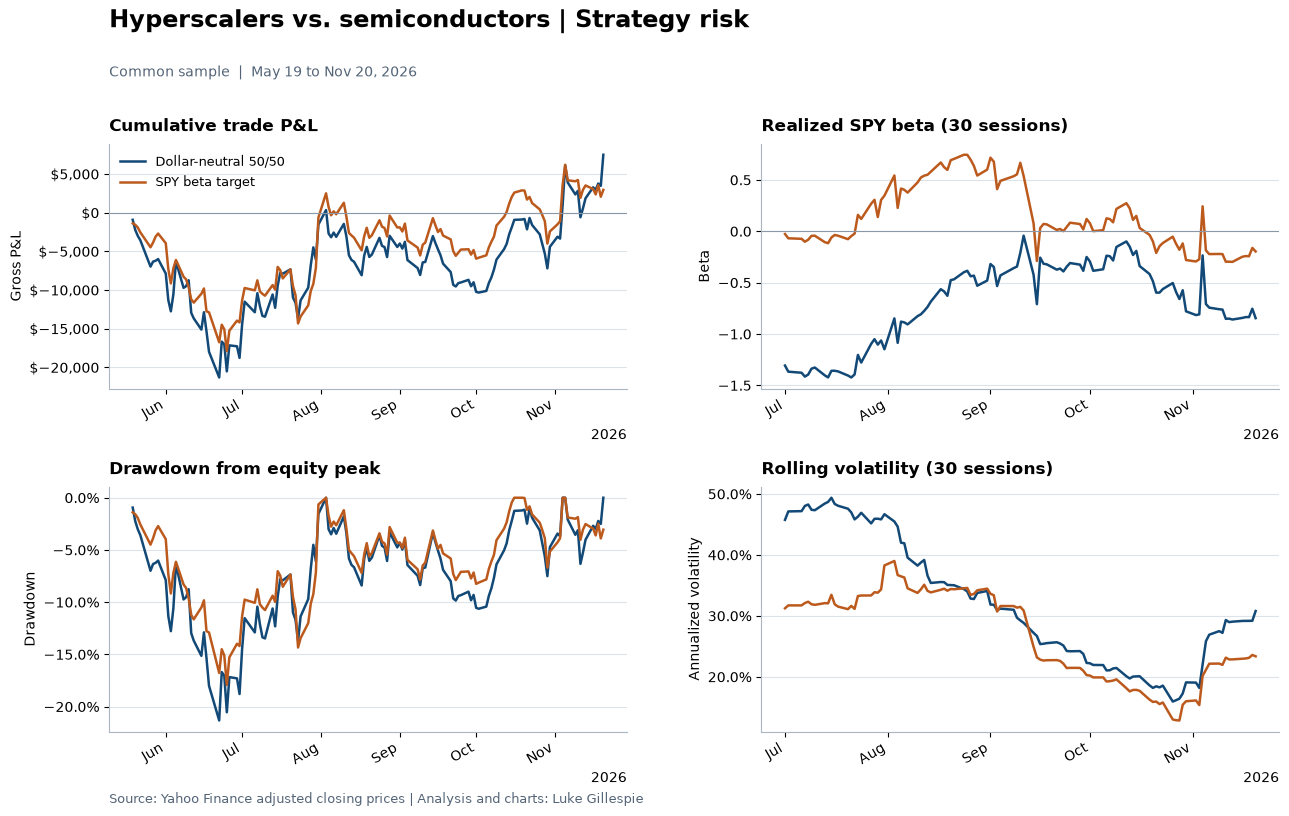

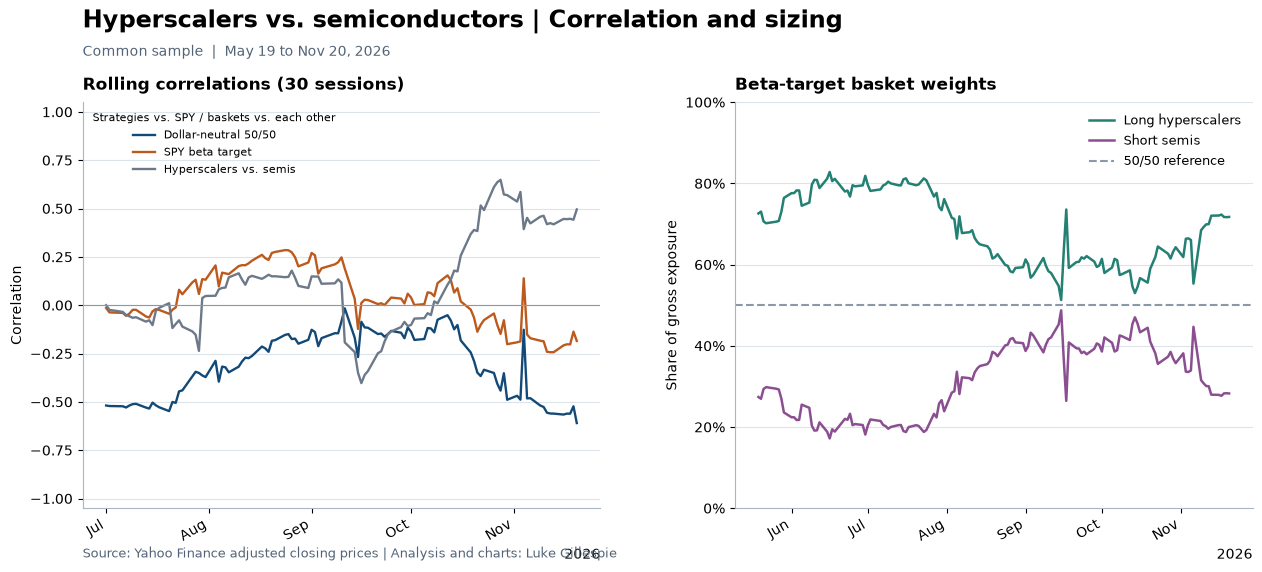

In [28]:
%run -i risk_and_factor_analysis.py

Hypothetical 90-day stress test | Opening gross exposure: $100,000

Cash funded · dollars added to gross P&L
Stock borrow fees          -107.88
ETF distributions owed      -86.30
Long dividends received     +49.32
Short proceeds interest      +0.00
Round-trip trading costs   -100.00
Net cash-funded cost: $245
Additional cost with a $25,000 margin debit: $308

                           Hyperscalers Semis    Long P&L    Short P&L    Gross P&L Net cash-funded Net with margin
Thesis plays out                    +2%  -15%   $1,000.00    $7,500.00    $8,500.00       $8,255.14       $7,946.92
Semis fall alone                    +0%  -10%       $0.00    $5,000.00    $5,000.00       $4,755.14       $4,446.92
Both sell off                       -5%  -10%  −$2,500.00    $5,000.00    $2,500.00       $2,255.14       $1,946.92
Equal selloff                      -10%  -10%  −$5,000.00    $5,000.00        $0.00        −$244.86        −$553.08
Hyperscalers fall alone             -5%   +0%  −$2,500.00 

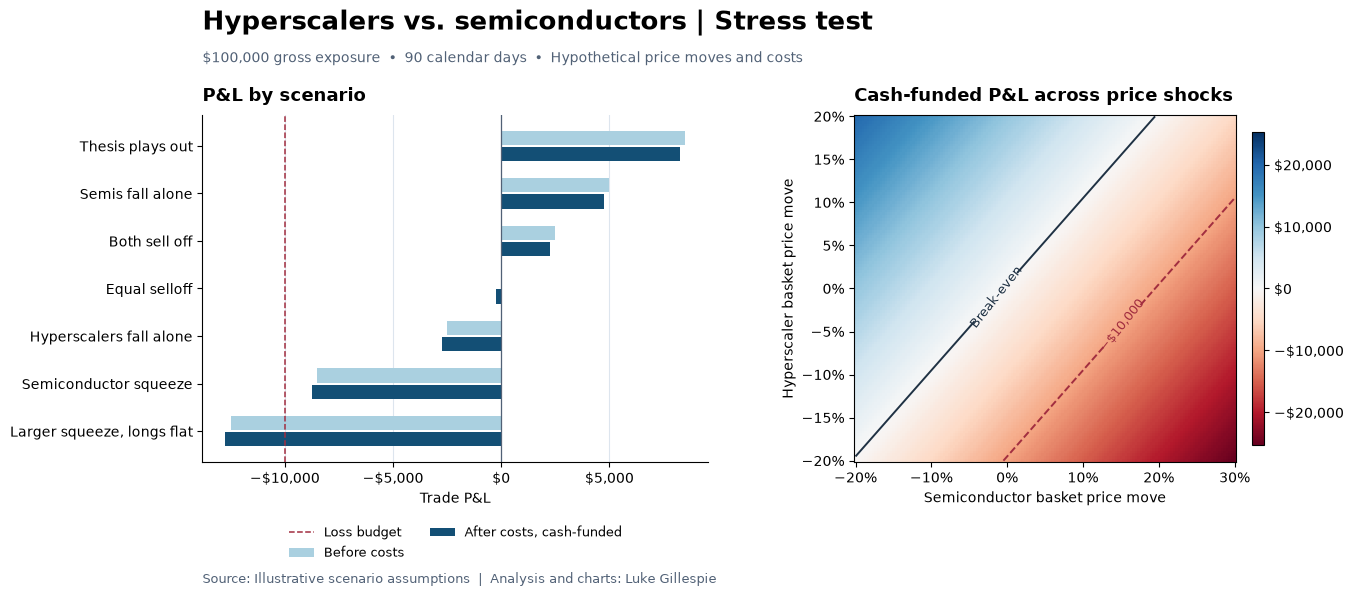

In [29]:
%run scenario_analysis.py

PART 4 — FUNDAMENTAL CATALYST EVENT STUDIES
Source-linked announcements: 18 | analyzed: 18
Common adjusted close sample: 2026-04-02 → 2026-11-20  (162 sessions)
Analysis dates / portfolio: 2026-04-06 → 2026-11-20 | 50% long/50% short on gross
EVENT TIMING: next US trading session after the publication date (conservative; NOT necessarily immediate price reaction)

Event table: 0 and 3 additional sessions | gross P&L (% of $100k gross), before costs
event_id published_date event_session             category day0_pct day0_to_day3_pct spy_adjusted_3_pct
     E01         Jun 10        Jun 11 Grid/interconnection   -4.20%           -4.13%             -0.29%
     E02         Jun 18        Jun 22 Grid/interconnection   -3.32%           -2.53%             -4.59%
     E03         Jun 22        Jun 23   Construction/power   +4.63%           +4.15%             +1.66%
     E04         Jul 14        Jul 15   Construction/power   +2.87%           +4.97%             +3.12%
     E05         Jul 22     

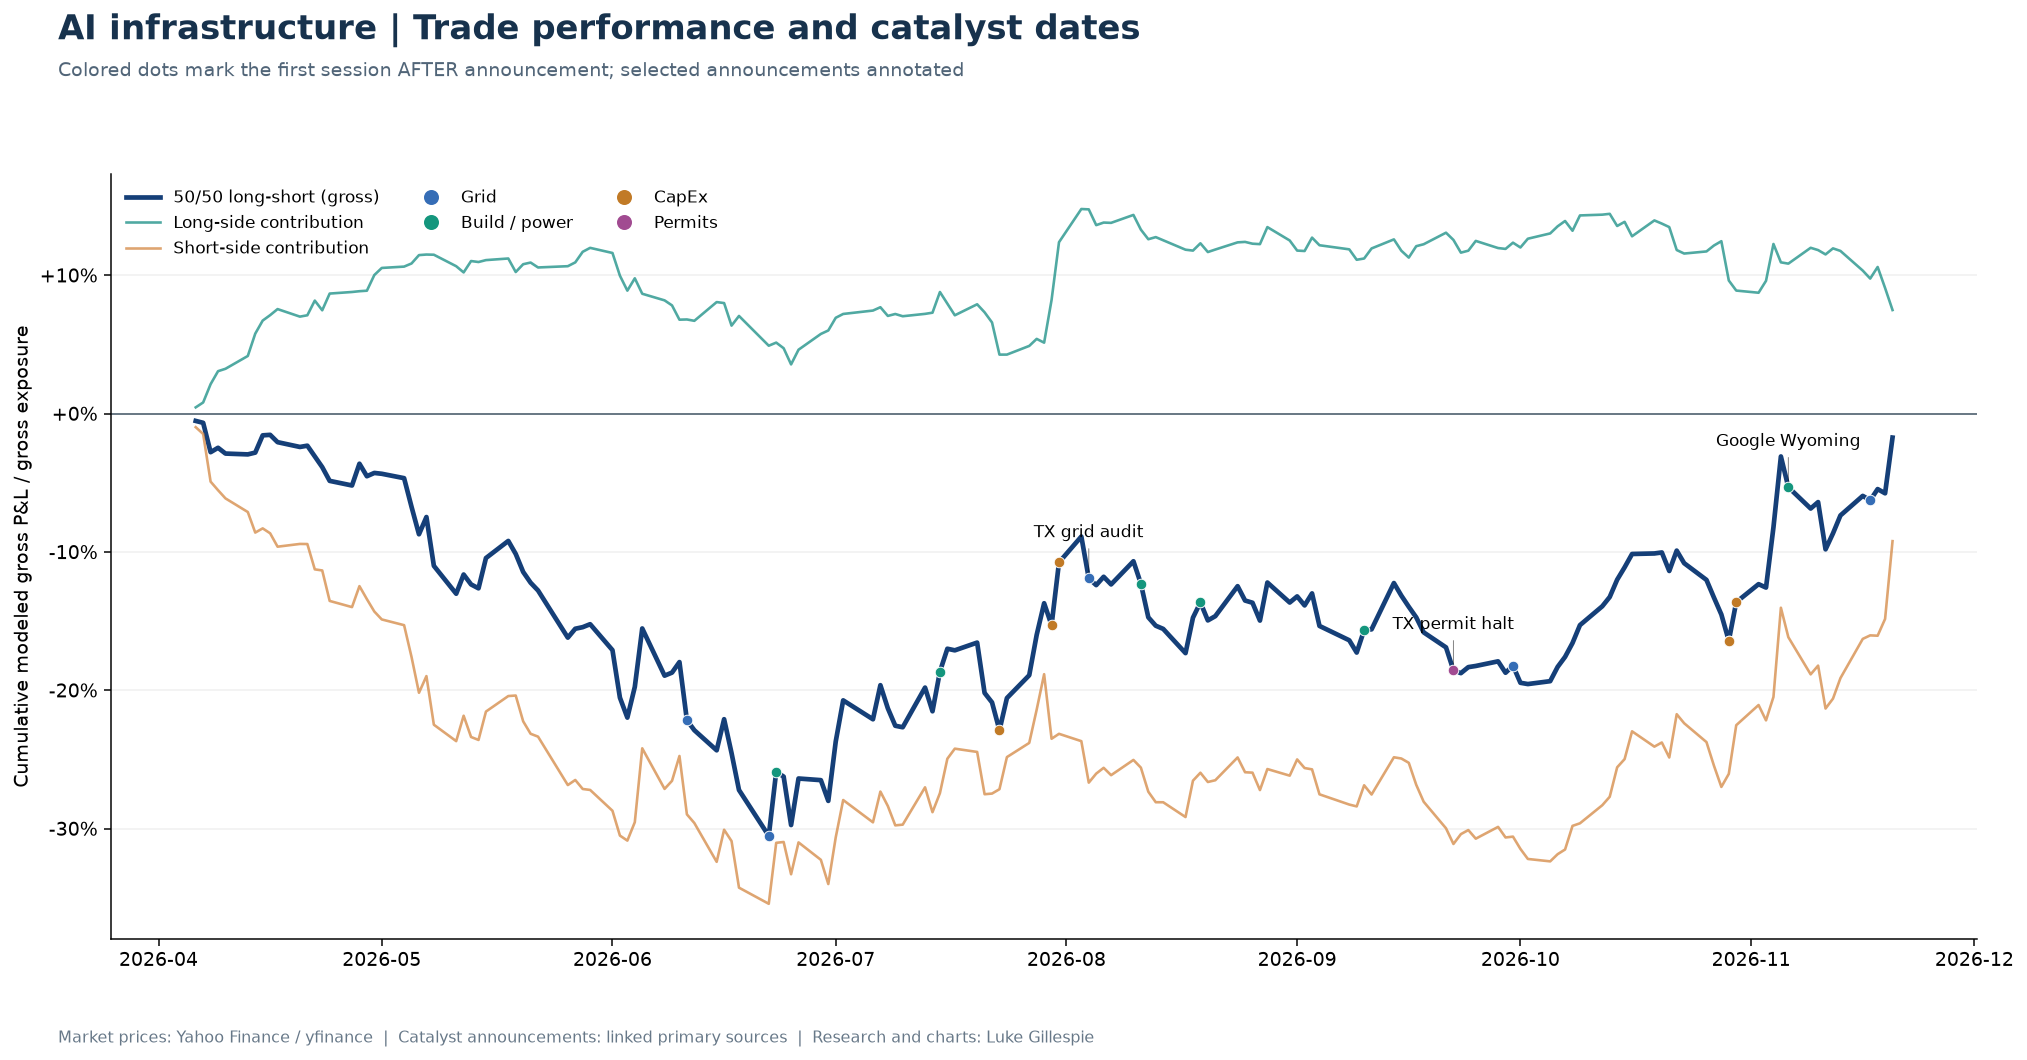

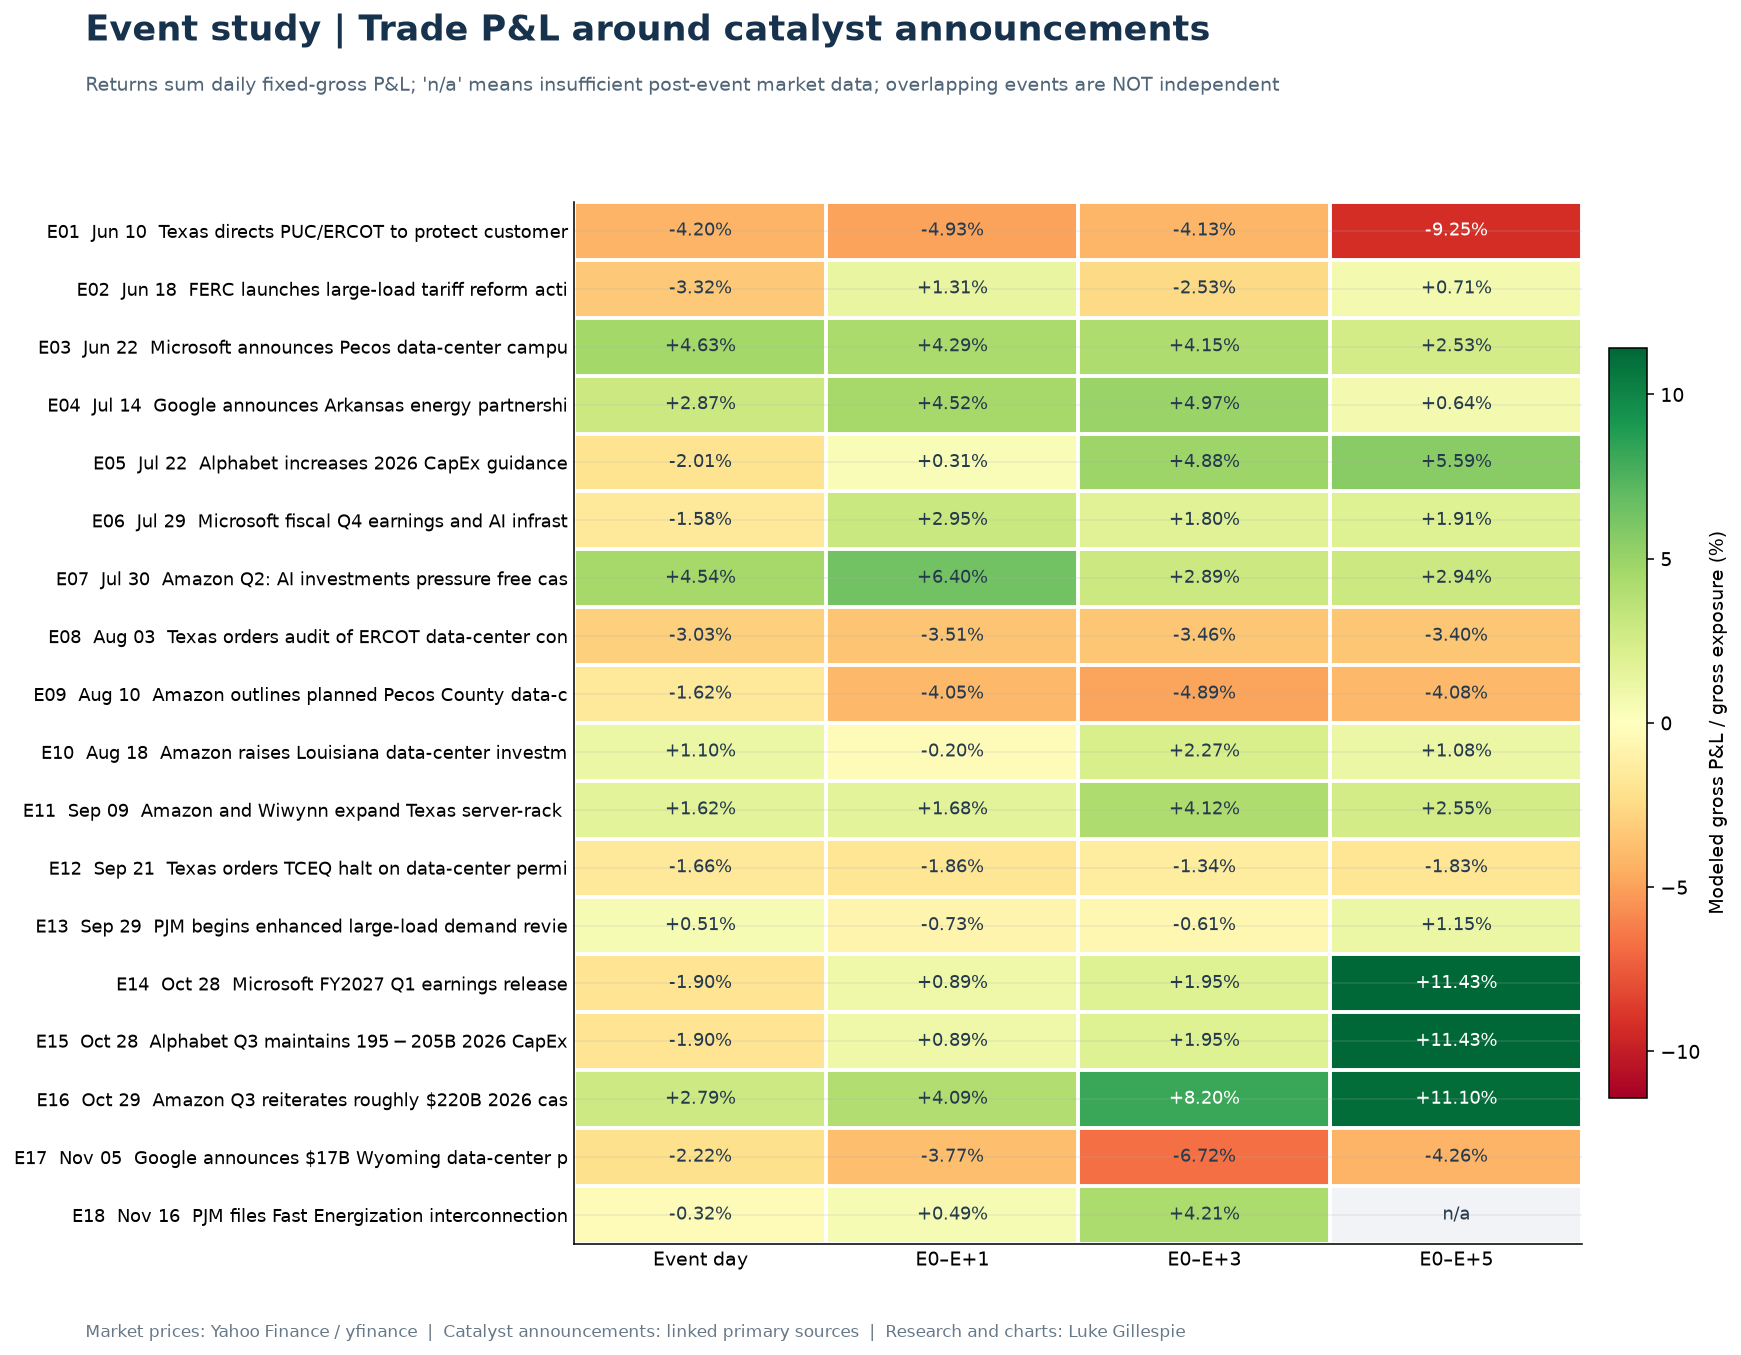

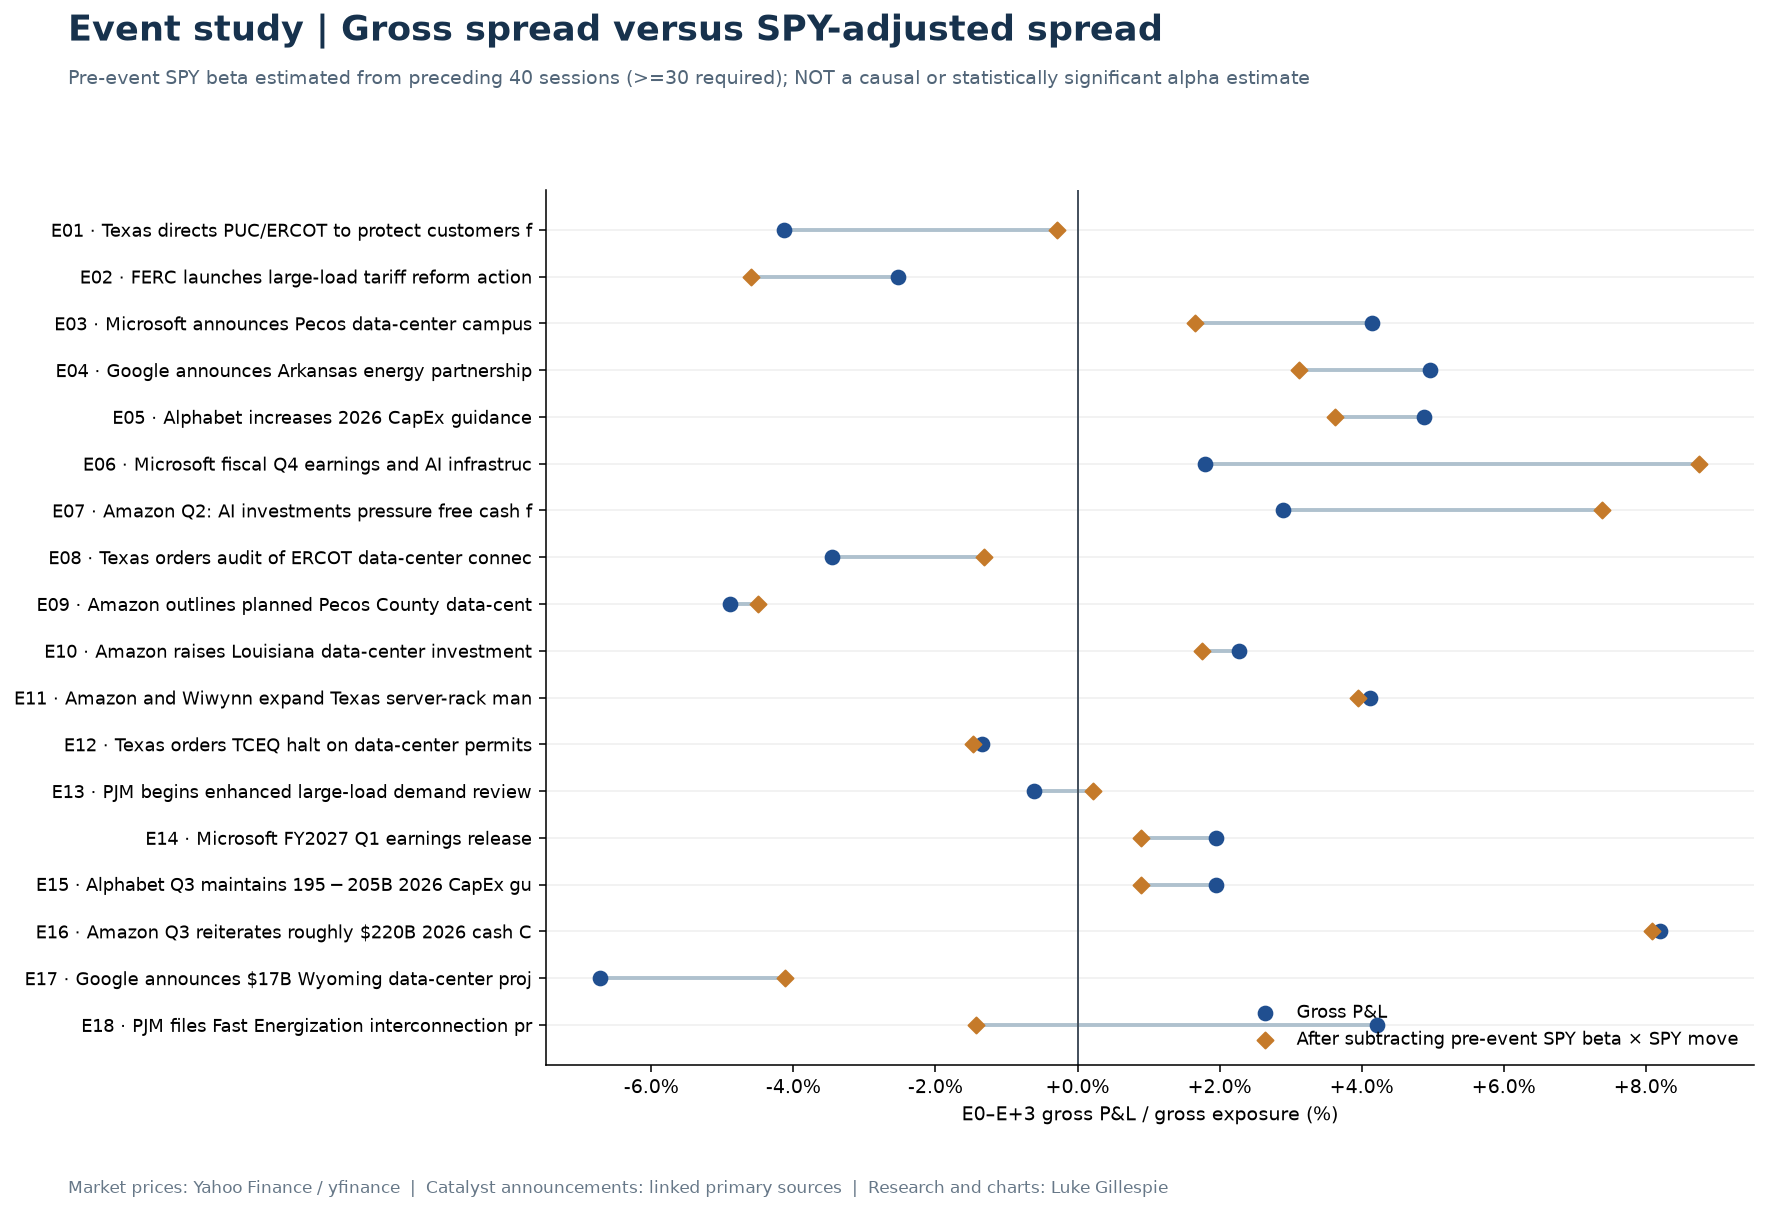

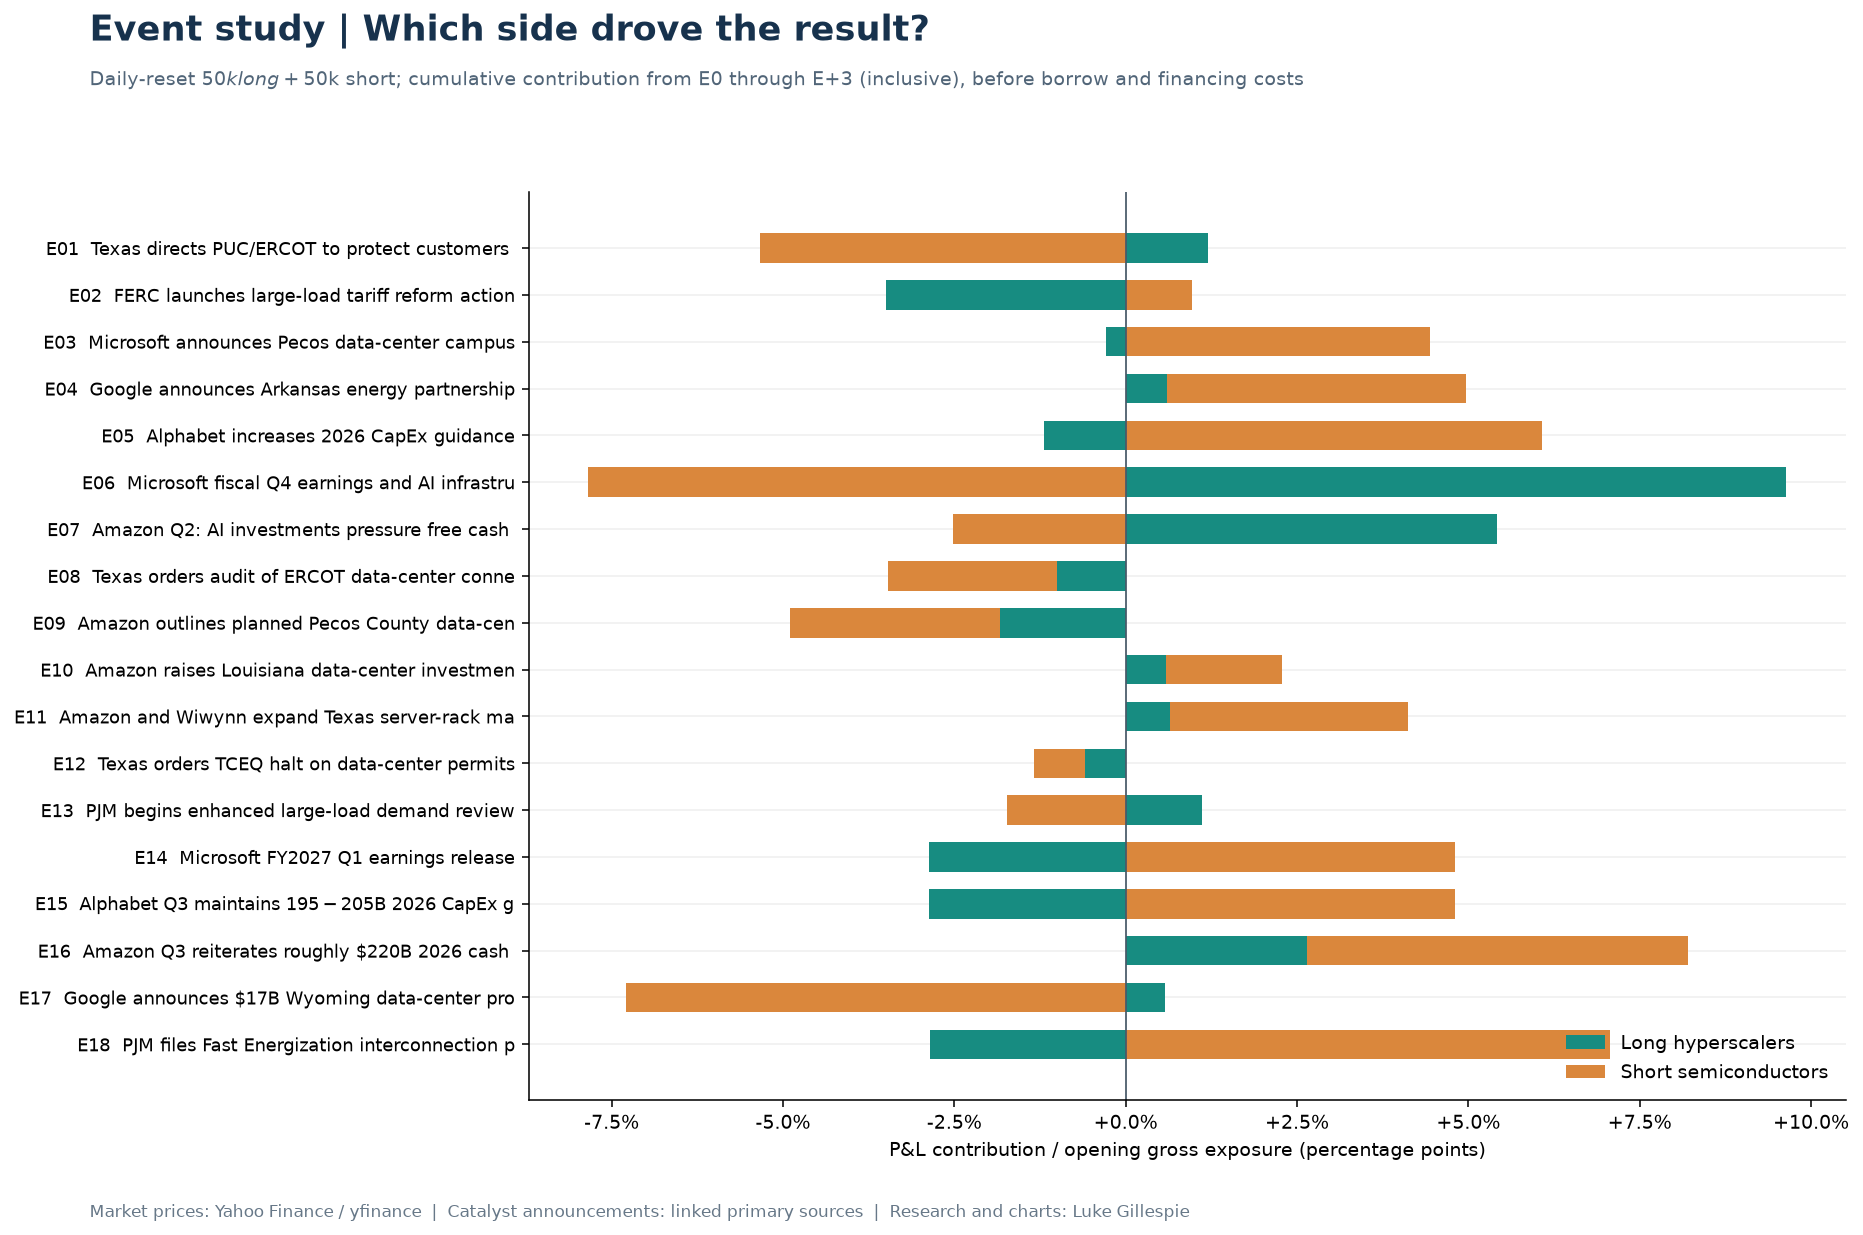

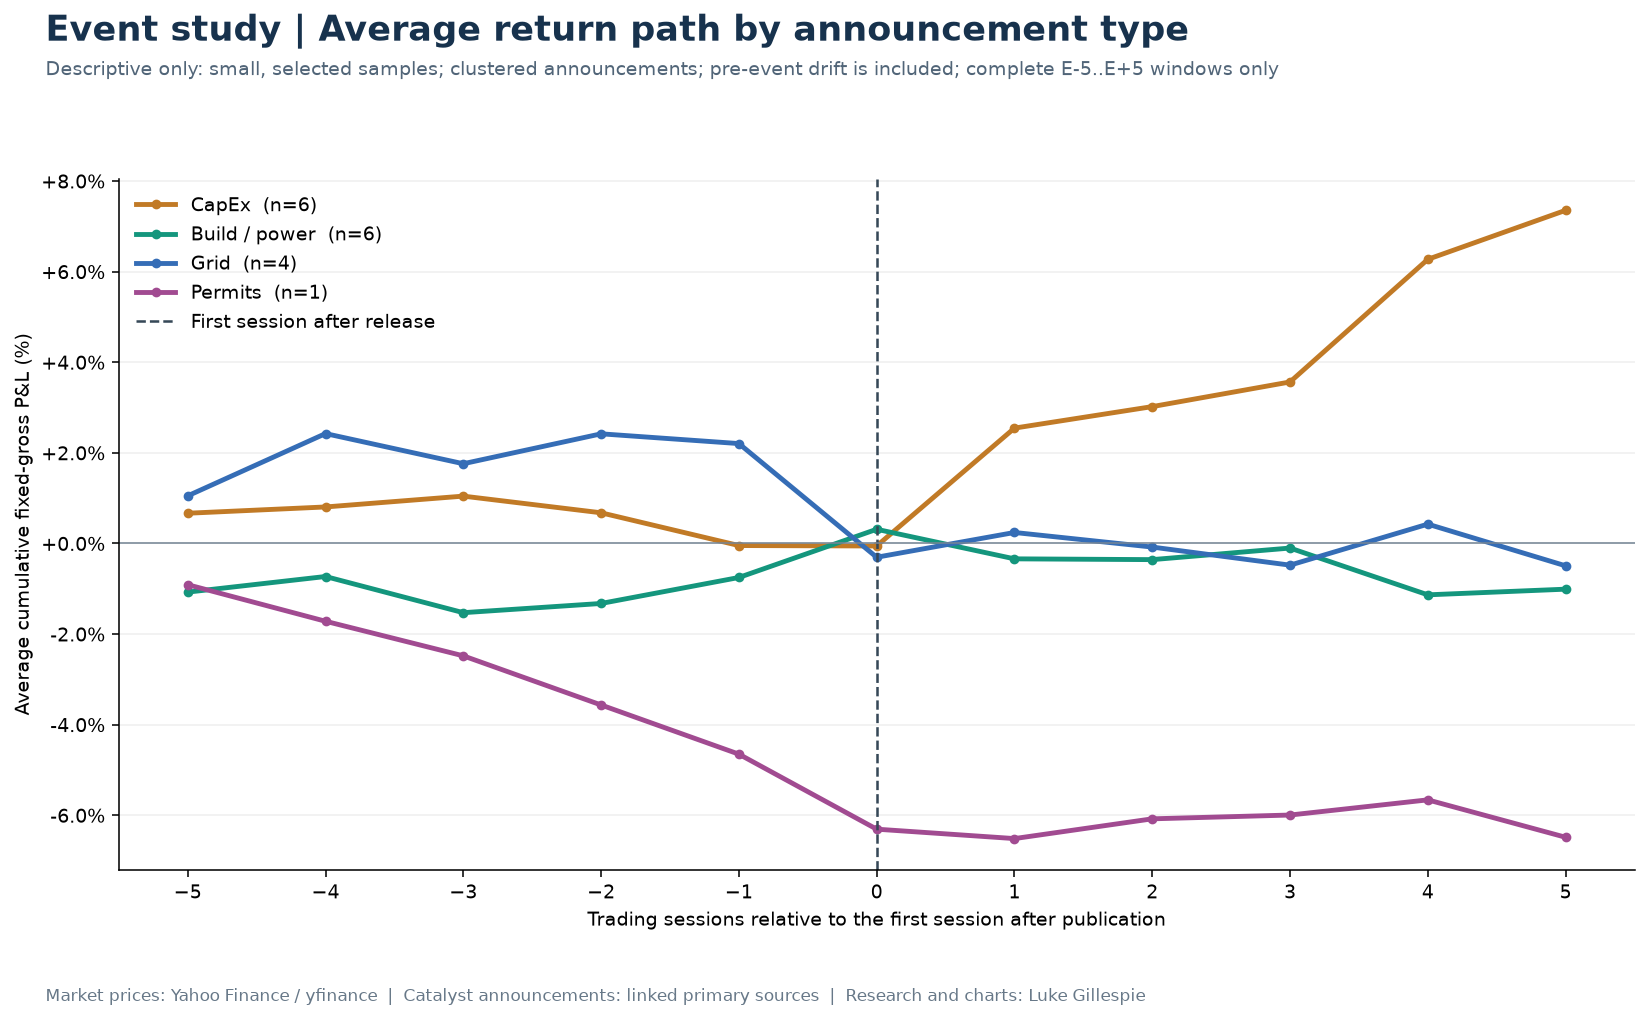

Complete 11-session windows by category: {'CapEx/earnings': 6, 'Construction/power': 6, 'Grid/interconnection': 4, 'Permitting': 1}

SAVED to: C:\Users\lukeg\Downloads\part4_outputs
   01_catalyst_timeline.png
   02_event_return_heatmap.png
   03_spy_adjusted_reactions.png
   04_long_short_attribution.png
   05_category_event_paths.png
   catalyst_event_results.csv
   catalyst_events.csv
   catalyst_research_notes.md
   fundamental_metrics.csv

Next: open catalyst_research_notes.md, check sources, and add the verified findings to your GitHub README.


In [30]:

%run fundamental_catalyst_research.py
